# Player Scouting & Similarity — Premier League 2015/16

**Question:** Which players play the same *way*, regardless of club, reputation or headline stats?
A recruitment team uses this to build replacement shortlists ("who plays like Kanté but costs less?").

**Data:** StatsBomb open event data — all 380 matches, ~1.3M events (passes, carries, shots, pressures, tackles…).

**Approach:**
1. Engineer per-90 features from raw events (incl. xA and possession-adjusted defending)
2. Reduce with PCA, cluster with K-Means into playing-style roles
3. Cosine similarity in PCA space for "players like X"
4. Validate: can a player's first-half profile find his own second-half profile?

In [1]:
import sys, json
sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.data import load_events, get_matches, get_nicknames
from src.features import build_player_table
from src.similarity import ScoutingModel, FEATURES
from src.evaluate import half_season_reidentification
from src import viz
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80)

## 1. Load events

In [2]:
events = load_events(2, 27)          # Premier League 2015/16
matches = get_matches(2, 27)
print(f"{len(events):,} events | {events.match_id.nunique()} matches")
events.type.value_counts().head(12)

1,313,773 events | 380 matches


type
Pass             368619
Ball Receipt*    340314
Carry            276949
Pressure         115402
Ball Recovery     40943
Duel              32290
Clearance         21645
Block             14839
Dribble           13721
Goal Keeper       11777
Miscontrol        10786
Dispossessed      10520
Name: count, dtype: int64

## 2. Feature engineering
Key decisions:
- **Minutes** rebuilt from Starting XI, substitutions and red cards; minimum 900 min (≈10 full games).
- **Per-90** rates so part-time players compare fairly.
- **xA** = xG of the shot each pass created.
- **Progressive** pass/carry = ball moved ≥25% closer to goal, ending outside the defending 40%.
- **PAdj defending** — tackles, interceptions, pressures scaled by `0.5 / opponent possession`, so a defender at a low-possession side isn't flattered by having more to do.

In [3]:
players = build_player_table(events, min_minutes=900)
players['player'] = players.index.to_series().map(get_nicknames(2, 27)).fillna(players.player)
print(players.shape)
players[['player','team','group','minutes','np_xg','xa','progressive_passes','tackles_won_padj','pressures_padj']].head(10).round(2)

(327, 35)


,player,team,group,minutes,np_xg,xa,progressive_passes,tackles_won_padj,pressures_padj
player_id,,,,,,,,,
3813,Wes Morgan,Leicester City,CB,3594.02,0.07,0.01,1.33,0.75,6.00
3815,Kasper Schmeichel,Leicester City,GK,3594.02,0.00,0.01,4.41,0.00,0.14
3344,Andrew Surman,AFC Bournemouth,CM,3591.57,0.02,0.06,4.34,0.78,14.09
20005,Toby Alderweireld,Tottenham Hotspur,CB,3569.18,0.08,0.01,5.19,0.75,7.03
3522,Heurelho Gomes,Watford,GK,3554.15,0.00,0.00,3.44,0.00,0.18
3608,Simon Francis,AFC Bournemouth,FB,3553.78,0.00,0.08,5.67,1.66,10.58
3523,Craig Dawson,West Bromwich Albion,FB,3548.67,0.09,0.05,4.08,0.82,9.49
4022,Darren Fletcher,West Bromwich Albion,CM,3533.58,0.05,0.05,4.56,0.57,11.61
3262,Łukasz Fabiański,Swansea City,GK,3492.20,0.00,0.00,3.04,0.00,0.15


Sanity check against the real season: Vardy scored 19 non-penalty goals and Özil made 19 assists.

In [4]:
chk = players[players.player.isin(['Jamie Vardy','Mesut Özil'])]
(chk[['np_goals','assists']].mul(chk.minutes/90, axis=0)).round(0).assign(player=chk.player)

,np_goals,assists,player
player_id,,,
10960,19.0,5.0,Jamie Vardy
3496,6.0,19.0,Mesut Özil


## 3. Model: PCA + K-Means roles

300 outfield players | 6 PCs keep 86% of variance


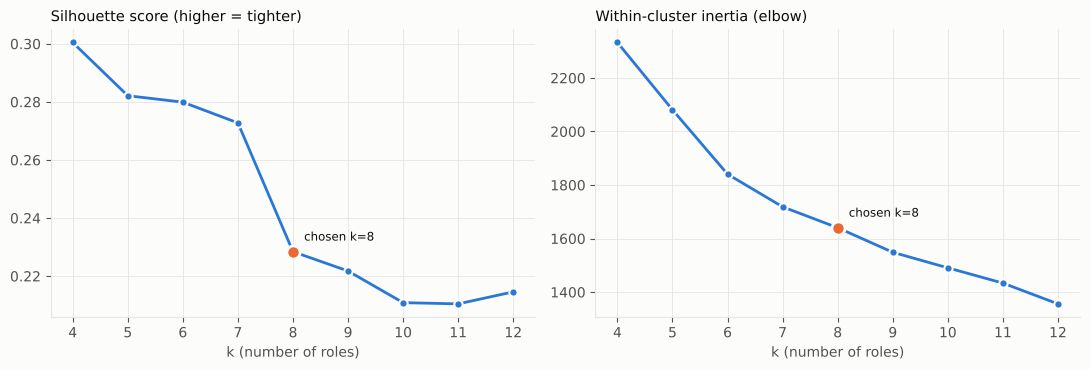

In [5]:
model = ScoutingModel(n_clusters=8).fit(players)
print(f"{len(model.players)} outfield players | {model.pca.n_components_} PCs keep "
      f"{model.pca.explained_variance_ratio_.sum():.0%} of variance")
diag = model.cluster_diagnostics()
viz.k_diagnostics(diag, 8); plt.show()

Silhouette favours fewer clusters (k=4 is basically CB / FB / midfield / attack — true but useless for scouting).
k=8 trades some compactness for roles a scout would recognise. Football styles form a continuum, so low silhouette is expected; the similarity search (below) does not depend on the cluster boundaries.

In [6]:
model.role_summary()

,role,players,defining_traits,examples
1,Ball-playing centre-back,60,"Clearances, Long passes, Interceptions (PAdj), Pass %","Wes Morgan, Toby Alderweireld, Ashley Williams, Steve Cook, Robert Huth"
0,Attacking full-back,52,"Crosses, Prog. passes, Passes, Clearances","Simon Francis, Craig Dawson, Aaron Cresswell, Charlie Daniels, Nacho Monreal"
2,Ball-winning midfielder,44,"Tackles won (PAdj), Interceptions (PAdj), Pressures (PAdj), Final-third entries","Andrew Surman, Eric Dier, Glenn Whelan, Daley Blind, Idrissa Gueye"
6,Penalty-box striker,36,"Non-pen xG, Aerial duels lost, Box touches, Shots","Harry Kane, Romelu Lukaku, Odion Ighalo, Jamie Vardy, Jermain Defoe"
5,Direct dribbling winger,33,"Prog. carries, Dribbles won, Crosses, Times dispossessed","Moussa Sissoko, Georginio Wijnaldum, Marko Arnautović, Anthony Martial, Sadi..."
4,Deep-lying playmaker,29,"Final-third entries, Recoveries, Passes, Through balls","Darren Fletcher, Yann M'Vila, Mark Noble, Danny Drinkwater, Matt Ritchie"
3,Creative playmaker,25,"xA, Passes into box, Through balls, Key passes","Ross Barkley, Mesut Özil, Riyad Mahrez, Christian Eriksen, Cesc Fàbregas"
7,Pressing second striker,21,"High pressures, Box touches, Pressures (PAdj), Shots","Troy Deeney, Gylfi Sigurðsson, André Ayew, Dan Gosling, Dele Alli"


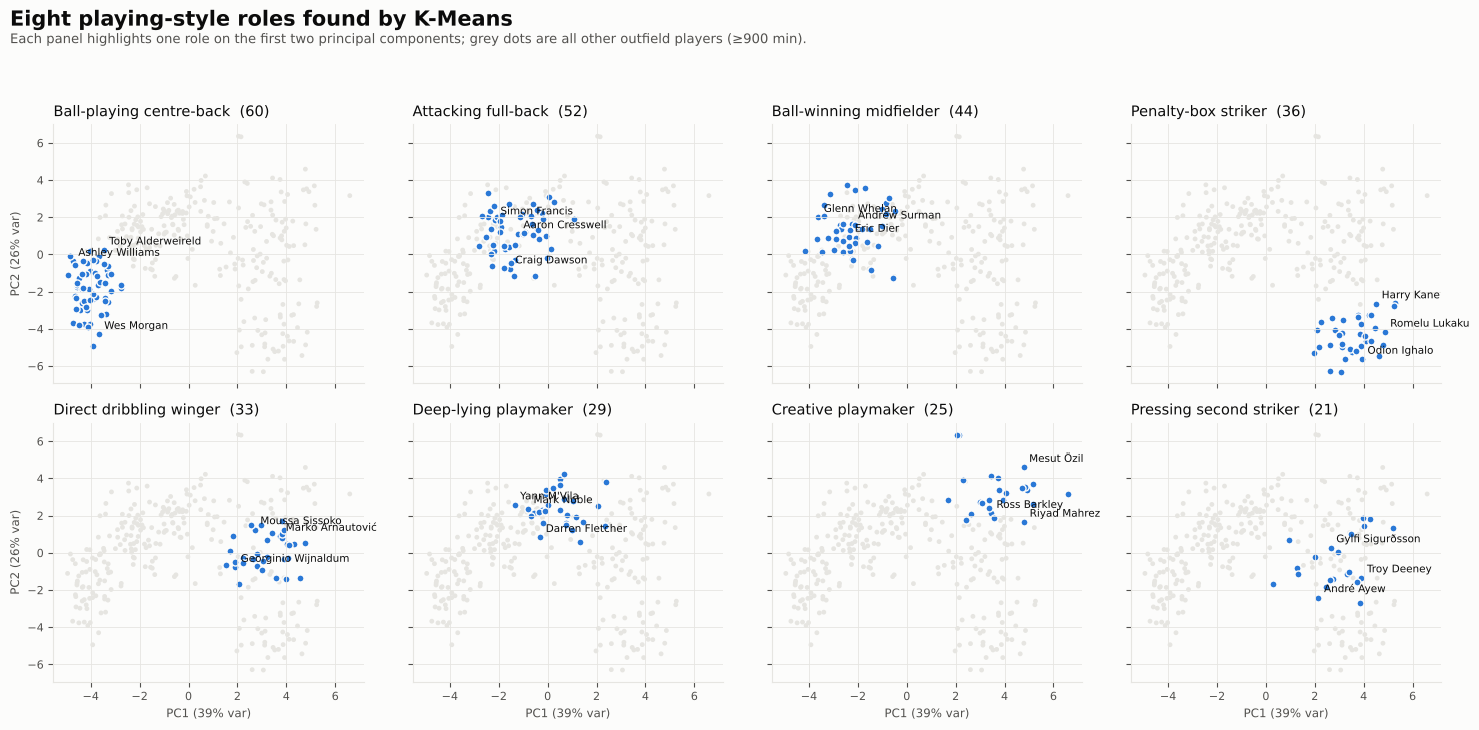

In [7]:
viz.role_map(model); plt.show()

## 4. Similarity search

In [8]:
model.similar("N'Golo Kanté", n=10)

,player,team,group,role,minutes,similarity
player_id,,,,,,
3436,Idrissa Gueye,Aston Villa,CM,Ball-winning midfielder,3203.416667,96.5
3037,Mousa Dembélé,Tottenham Hotspur,CM,Ball-winning midfielder,2348.933333,93.7
3462,Jack Cork,Swansea City,CM,Ball-winning midfielder,2675.766667,93.3
12325,Baba Rahman,Chelsea,FB,Ball-winning midfielder,1072.916667,92.8
3464,James McArthur,Crystal Palace,CM,Ball-winning midfielder,2265.783333,92.4
3437,Francis Coquelin,Arsenal,CM,Ball-winning midfielder,1707.516667,92.1
3721,Étienne Capoue,Watford,CM,Deep-lying playmaker,2933.766667,90.9
9578,Jonathan Howson,Norwich City,CM,Attacking full-back,3088.600000,90.7
42900,Cheik Tioté,Newcastle United,CM,Ball-winning midfielder,1262.750000,90.0


In [9]:
# Replacement search: wingers/forwards like Mahrez at other clubs
model.similar("Riyad Mahrez", n=8, other_teams=True)

,player,team,group,role,minutes,similarity
player_id,,,,,,
3286,Nathan Redmond,Norwich City,W,Direct dribbling winger,2461.933333,99.5
3463,Junior Stanislas,AFC Bournemouth,W,Creative playmaker,1493.250000,98.4
16457,Jeremain Lens,Sunderland,W,Direct dribbling winger,1352.866667,97.8
3196,Wahbi Khazri,Sunderland,W,Direct dribbling winger,1104.783333,97.8
3831,Dušan Tadić,Southampton,W,Creative playmaker,2348.200000,94.7
19688,Jason Puncheon,Crystal Palace,AM,Creative playmaker,2705.200000,94.5
5581,Joel Campbell,Arsenal,W,Pressing second striker,913.633333,94.5
3958,Pedro,Chelsea,W,Direct dribbling winger,2112.583333,94.4


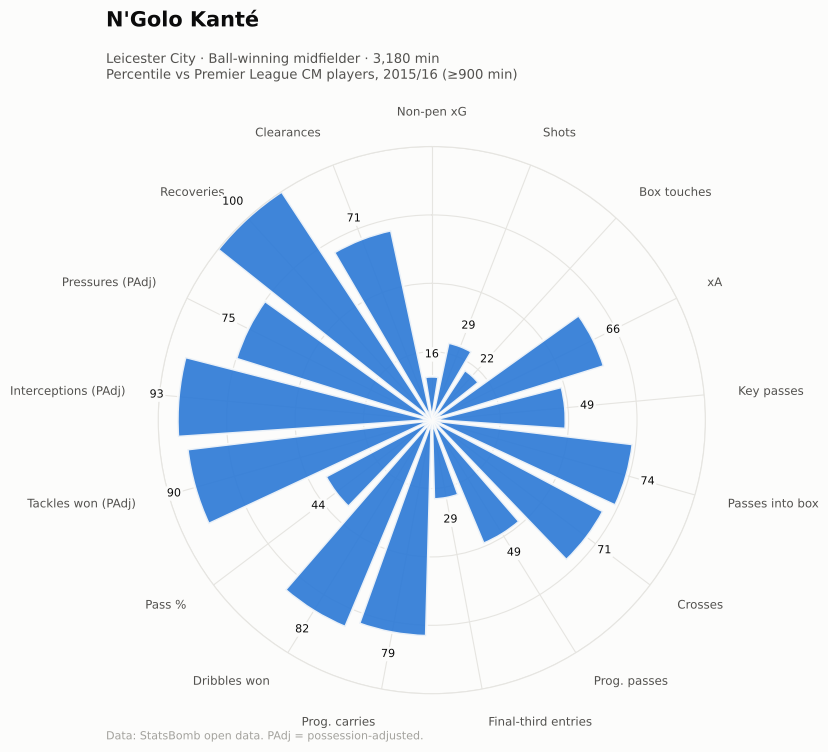

In [10]:
viz.pizza(model, "N'Golo Kanté"); plt.show()

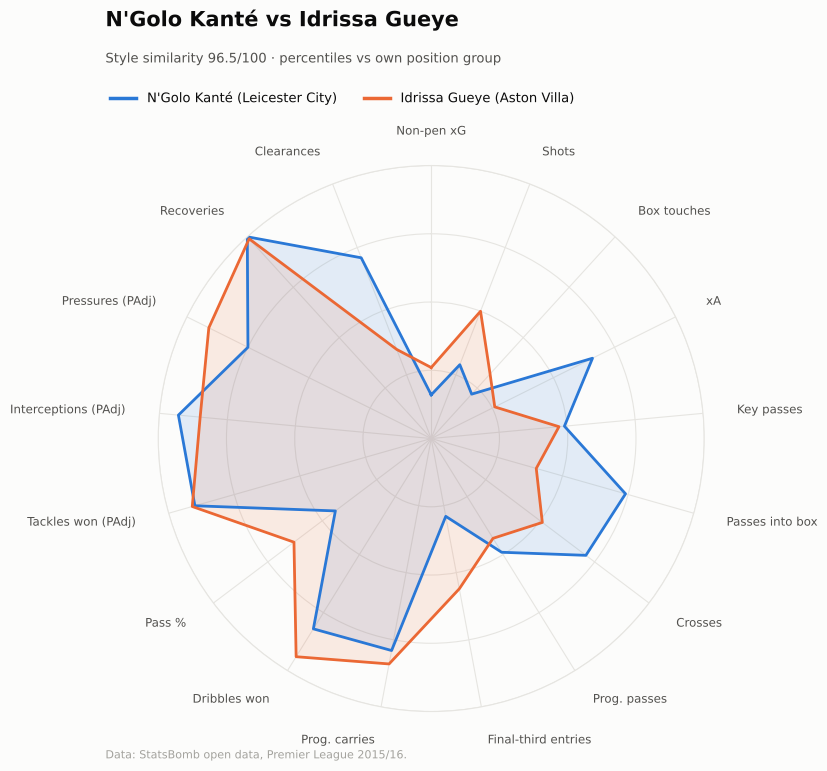

In [11]:
viz.compare(model, "N'Golo Kanté", "Idrissa Gueye"); plt.show()

## 5. Validation — is it measuring *style* or noise?
Split the season at the halfway date. Fit scaler + PCA on the first half only, then for each player rank all second-half profiles by similarity to his first-half profile. A stable style signature should rank himself near the top.

In [12]:
m = half_season_reidentification(events, matches)
print(json.dumps({k: (round(v,3) if isinstance(v,float) else v) for k,v in m.items()}, indent=2))

{
  "cutoff_date": "2016-01-02",
  "players_tested": 203,
  "candidates": 264,
  "top1": 0.281,
  "top5": 0.611,
  "top10": 0.759,
  "median_rank": 3.0,
  "random_top5": 0.019,
  "position_only_top5": 0.118
}


**Result:** the player's own profile is the #1 match 28% of the time and top-5 61% of the time, out of ~260 candidates — vs 1.9% by chance and ~12% if you only knew his position. The features capture a stable, individual playing style.

## 6. Limitations & next steps
- One season, one league, 2015/16 — swap in other StatsBomb competitions via `load_events(comp, season)`.
- Event data has no off-ball movement; tracking data would add runs and spacing.
- Position is the event-weighted mode; multi-role players are blurred.
- Next: weight features by what a club values, add age/contract/market value for real shortlists, or use a learned embedding (e.g. autoencoder on action sequences).